<a href="https://colab.research.google.com/github/Nurfinkaa/PCVK_Ganjil_2026/blob/main/Week7_21.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **TUGAS PRAKTIKUM**

In [53]:
# ===== SEL IDENTITAS KELOMPOK =====
NAMA = 'Nurfinka Lailasari'
NIM = '244107020211'

print("=" * 65)
print("PRAKTIKUM 7: SEGMENTASI CITRA DENGAN THRESHOLDING & OCR")
print(f"Koordinator / Pengunggah: {NAMA} (NIM: {NIM})")
print("-" * 65)

PRAKTIKUM 7: SEGMENTASI CITRA DENGAN THRESHOLDING & OCR
Koordinator / Pengunggah: Nurfinka Lailasari (NIM: 244107020211)
-----------------------------------------------------------------


## **Tugas Individu**

> **import folder yang ada di Drive**

In [13]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
import os
base = '/content/drive/MyDrive/PCVK/Images/'
print("Folder ada:", os.path.exists(base))
if os.path.exists(base):
    print(os.listdir(base))

Folder ada: True
['galaxy.jpg', 'noises-image.zip', '244107020211', 'lena.jpg', 'lena_lc.jpg', 'mandrill.tiff', 'djawatan.jpg', 'sudoku-original.jpg', 'ktp_fulani.jpg', 'ktp_fulan.jpg', 'jungle.png', 'lily.jpg', 'lena_gs_lc2.jpg', 'gradient.jpg', 'KTM KELOMPOK']


> **Import beberapa library**

In [15]:
#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

> **Global Threshold (BINARY, BINARY_INV, TRUNC, TOZERO, TOZERO_INV), dengan
threshold= 200**

BINARY      sama dengan OpenCV: True
BINARY_INV  sama dengan OpenCV: True
TRUNC       sama dengan OpenCV: True
TOZERO      sama dengan OpenCV: True
TOZERO_INV  sama dengan OpenCV: True


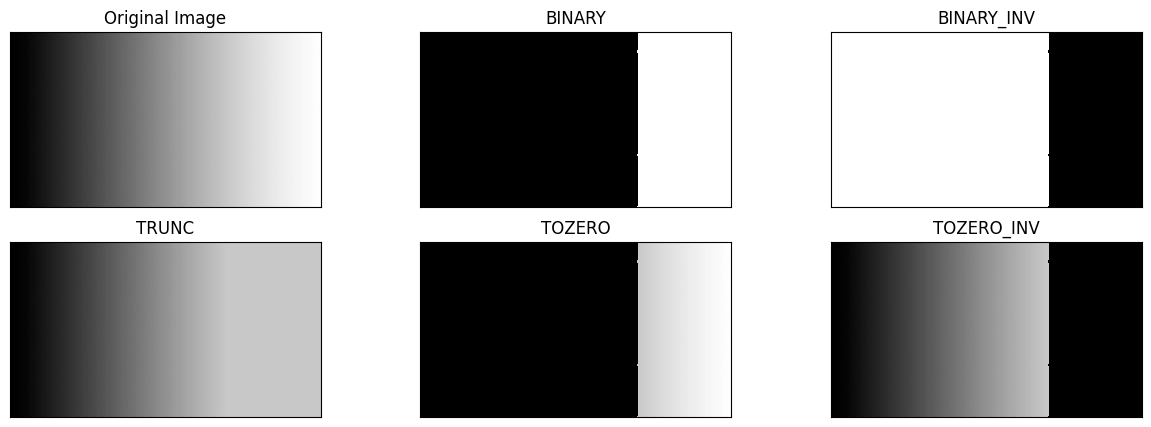

In [16]:
def global_threshold_manual(img, thresh=200, maxval=255):
    src = img.astype(np.int16)
    atas = src > thresh                      # True jika nilai piksel > thresh
    hasil = {
        'BINARY'    : np.where(atas, maxval, 0),
        'BINARY_INV': np.where(atas, 0, maxval),
        'TRUNC'     : np.where(atas, thresh, src),
        'TOZERO'    : np.where(atas, src, 0),
        'TOZERO_INV': np.where(atas, 0, src),
    }
    return {k: v.astype(np.uint8) for k, v in hasil.items()}

filename = '/content/drive/MyDrive/PCVK/Images/gradient.jpg'
img = cv.imread(filename, cv.IMREAD_GRAYSCALE)
assert img is not None, f"File tidak ditemukan: {filename}"

T3 = 200
hasil3 = global_threshold_manual(img, T3)

# Pengecekan terhadap OpenCV (opsional, hanya untuk verifikasi)
cv_flag = {'BINARY': cv.THRESH_BINARY, 'BINARY_INV': cv.THRESH_BINARY_INV,
           'TRUNC': cv.THRESH_TRUNC, 'TOZERO': cv.THRESH_TOZERO,
           'TOZERO_INV': cv.THRESH_TOZERO_INV}
for k, flag in cv_flag.items():
    _, ref = cv.threshold(img, T3, 255, flag)
    print(f"{k:11s} sama dengan OpenCV: {np.array_equal(ref, hasil3[k])}")

titles = ['Original Image'] + list(hasil3.keys())
images = [img] + list(hasil3.values())

plt.figure(figsize=(15, 5))
for i in range(len(images)):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], 'gray', vmin=0, vmax=255, interpolation='nearest')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

> **Program Addaptive Threshold**

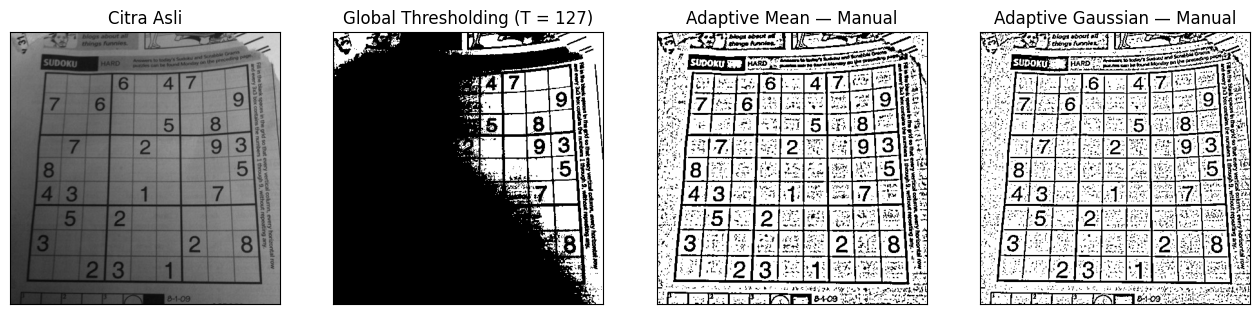

In [17]:
filename = '/content/drive/MyDrive/PCVK/Images/sudoku-original.jpg'
gray = cv.imread(filename, cv.IMREAD_GRAYSCALE)
assert gray is not None, f"File tidak ditemukan: {filename}"

def global_manual(gray, T=127):
    return np.where(gray > T, 255, 0).astype(np.uint8)

def pad_reflect(img, r):
    return np.pad(img.astype(np.float64), r, mode='reflect')

def mean_lokal(gray, b):
    r = b // 2
    p = pad_reflect(gray, r)
    ii = np.pad(p.cumsum(axis=0).cumsum(axis=1), ((1, 0), (1, 0)))   # integral image
    H, W = gray.shape
    s = ii[b:b+H, b:b+W] - ii[0:H, b:b+W] - ii[b:b+H, 0:W] + ii[0:H, 0:W]
    return s / (b * b)

def kernel_gauss_1d(b, sigma):
    r = b // 2
    x = np.arange(-r, r + 1)
    k = np.exp(-(x ** 2) / (2 * sigma ** 2))
    return k / k.sum()

def gauss_lokal(gray, b, sigma):
    r = b // 2
    p = pad_reflect(gray, r)
    k = kernel_gauss_1d(b, sigma)
    H, W = gray.shape
    tmp = sum(k[i] * p[:, i:i+W] for i in range(b))      # konvolusi horizontal
    return sum(k[i] * tmp[i:i+H, :] for i in range(b))   # konvolusi vertikal

def adaptive_manual(gray, metode='mean', b=11, C=2, sigma=2):
    lokal = mean_lokal(gray, b) if metode == 'mean' else gauss_lokal(gray, b, sigma)
    T = lokal - C                                        # T(x,y) = rata-rata lokal - C
    return np.where(gray > T, 255, 0).astype(np.uint8)

th_global = global_manual(gray, 127)
th_mean   = adaptive_manual(gray, 'mean', b=11, C=2)
th_gauss  = adaptive_manual(gray, 'gauss', b=11, C=2, sigma=2)

titles = ['Citra Asli', 'Global Thresholding (T = 127)',
          'Adaptive Mean — Manual', 'Adaptive Gaussian — Manual']
citra2 = [gray, th_global, th_mean, th_gauss]

plt.figure(figsize=(16, 5))
for i in range(4):
    plt.subplot(1, 4, i+1)
    plt.imshow(citra2[i], 'gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

Threshold Otsu manual: 95
Threshold Otsu library: 94


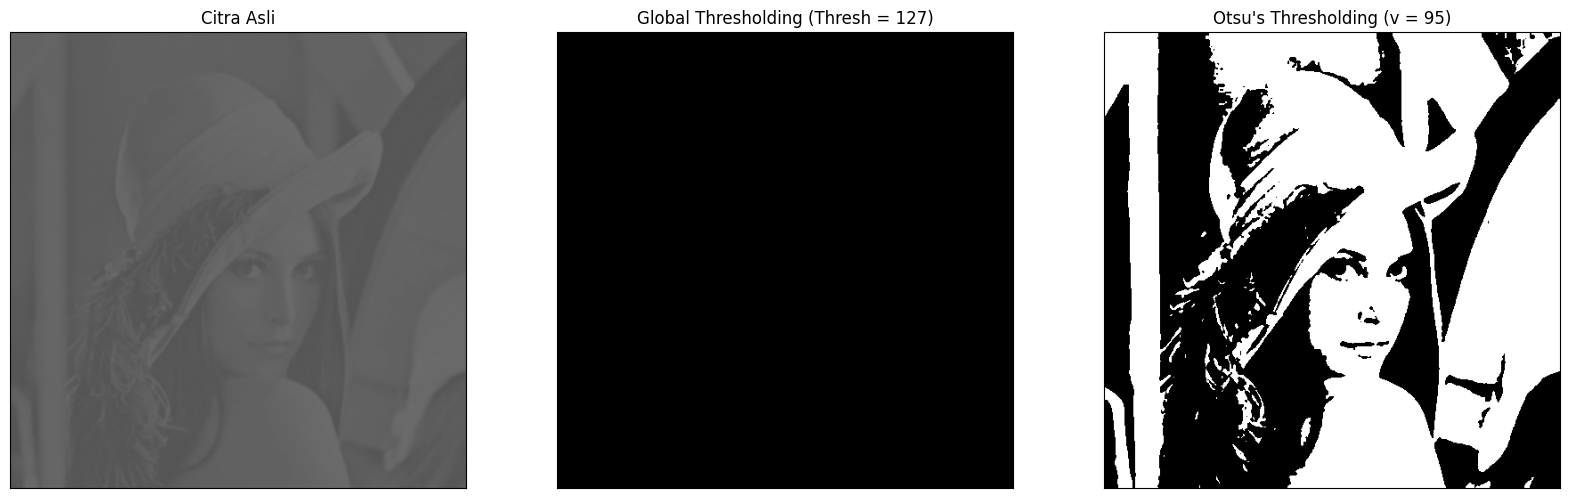

In [18]:
filename = ('/content/drive/MyDrive/PCVK/Images/lena_gs_lc2.jpg')
img = cv.imread(filename, 0)
assert img is not None, f"File tidak ditemukan: {filename}"
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        if pcb == 0 or pcf == 0:              # perbaikan 1: lewati t yang salah satu kelasnya kosong
            continue
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = np.where(gray > final_thresh, 255, 0).astype(np.uint8)   # perbaikan 2: semua piksel jadi 0/255
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
print("Threshold Otsu manual:", otsu_thresh)    # perbaikan 3: nilai threshold ditampilkan

x = ("Otsu's Thresholding (v = ") + str(otsu_thresh) + ")"
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

# Pembanding: Otsu dengan library
ret_lib, th_lib = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
print("Threshold Otsu library:", int(ret_lib))

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 15))
for i in range(len(citra3)):
    plt.subplot(1, 3, i+1), plt.imshow(citra3[i], 'gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

Rentang intensitas : 15 - 255
Threshold Otsu     : 166
Piksel putih global (T=127): 88.5%
Piksel putih Otsu (T=166): 84.2%


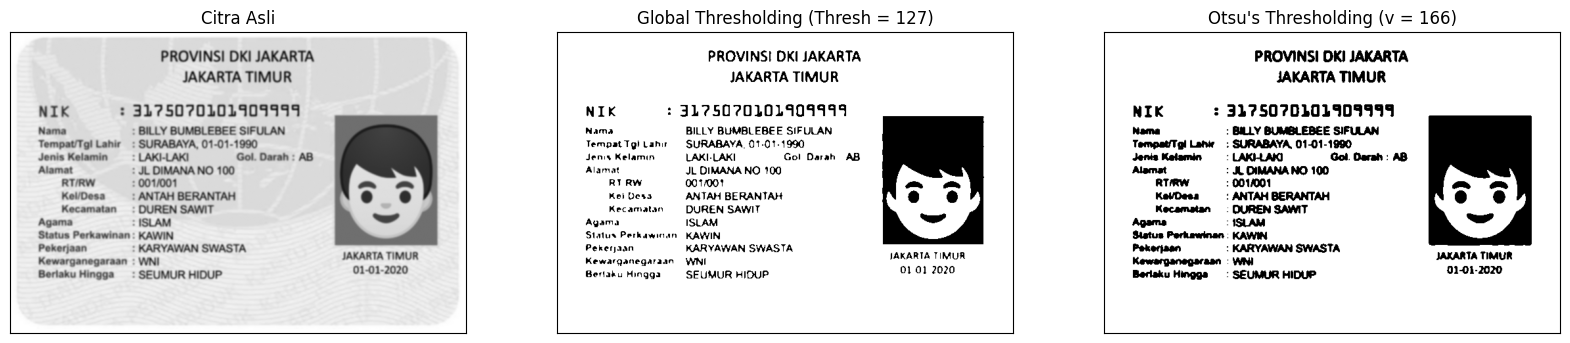

In [19]:
FILE_KTP = 'ktp_fulan.jpg'     # ganti dengan nama file KTP Anda, misalnya 'ktp_fulani.jpg'
filename = '/content/drive/MyDrive/PCVK/Images/' + FILE_KTP
img = cv.imread(filename, 0)
assert img is not None, f"File tidak ditemukan: {filename}"
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        if pcb == 0 or pcf == 0:
            continue
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight
        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2
        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = np.where(gray > final_thresh, 255, 0).astype(np.uint8)
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

print("Rentang intensitas :", blur.min(), "-", blur.max())
print("Threshold Otsu     :", otsu_thresh)
print(f"Piksel putih global (T=127): {(th1 == 255).mean()*100:.1f}%")
print(f"Piksel putih Otsu (T={otsu_thresh}): {(otsu_biner == 255).mean()*100:.1f}%")

x = "Otsu's Thresholding (v = " + str(otsu_thresh) + ")"
titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 7))
for i in range(len(citra3)):
    plt.subplot(1, 3, i+1), plt.imshow(citra3[i], 'gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

> Segmentasi Berbasis Region

Ukuran citra: (303, 384)
Seed di dalam koin   T =  5 ->     21 piksel
Seed di dalam koin   T = 20 ->    919 piksel
Seed di dalam koin   T = 60 ->  15253 piksel
Seed di latar        T =  5 ->    280 piksel
Seed di latar        T = 20 ->   5532 piksel
Seed di latar        T = 60 ->  39811 piksel
Seed di tepi koin    T =  5 ->      1 piksel
Seed di tepi koin    T = 20 ->     27 piksel
Seed di tepi koin    T = 60 ->  40219 piksel


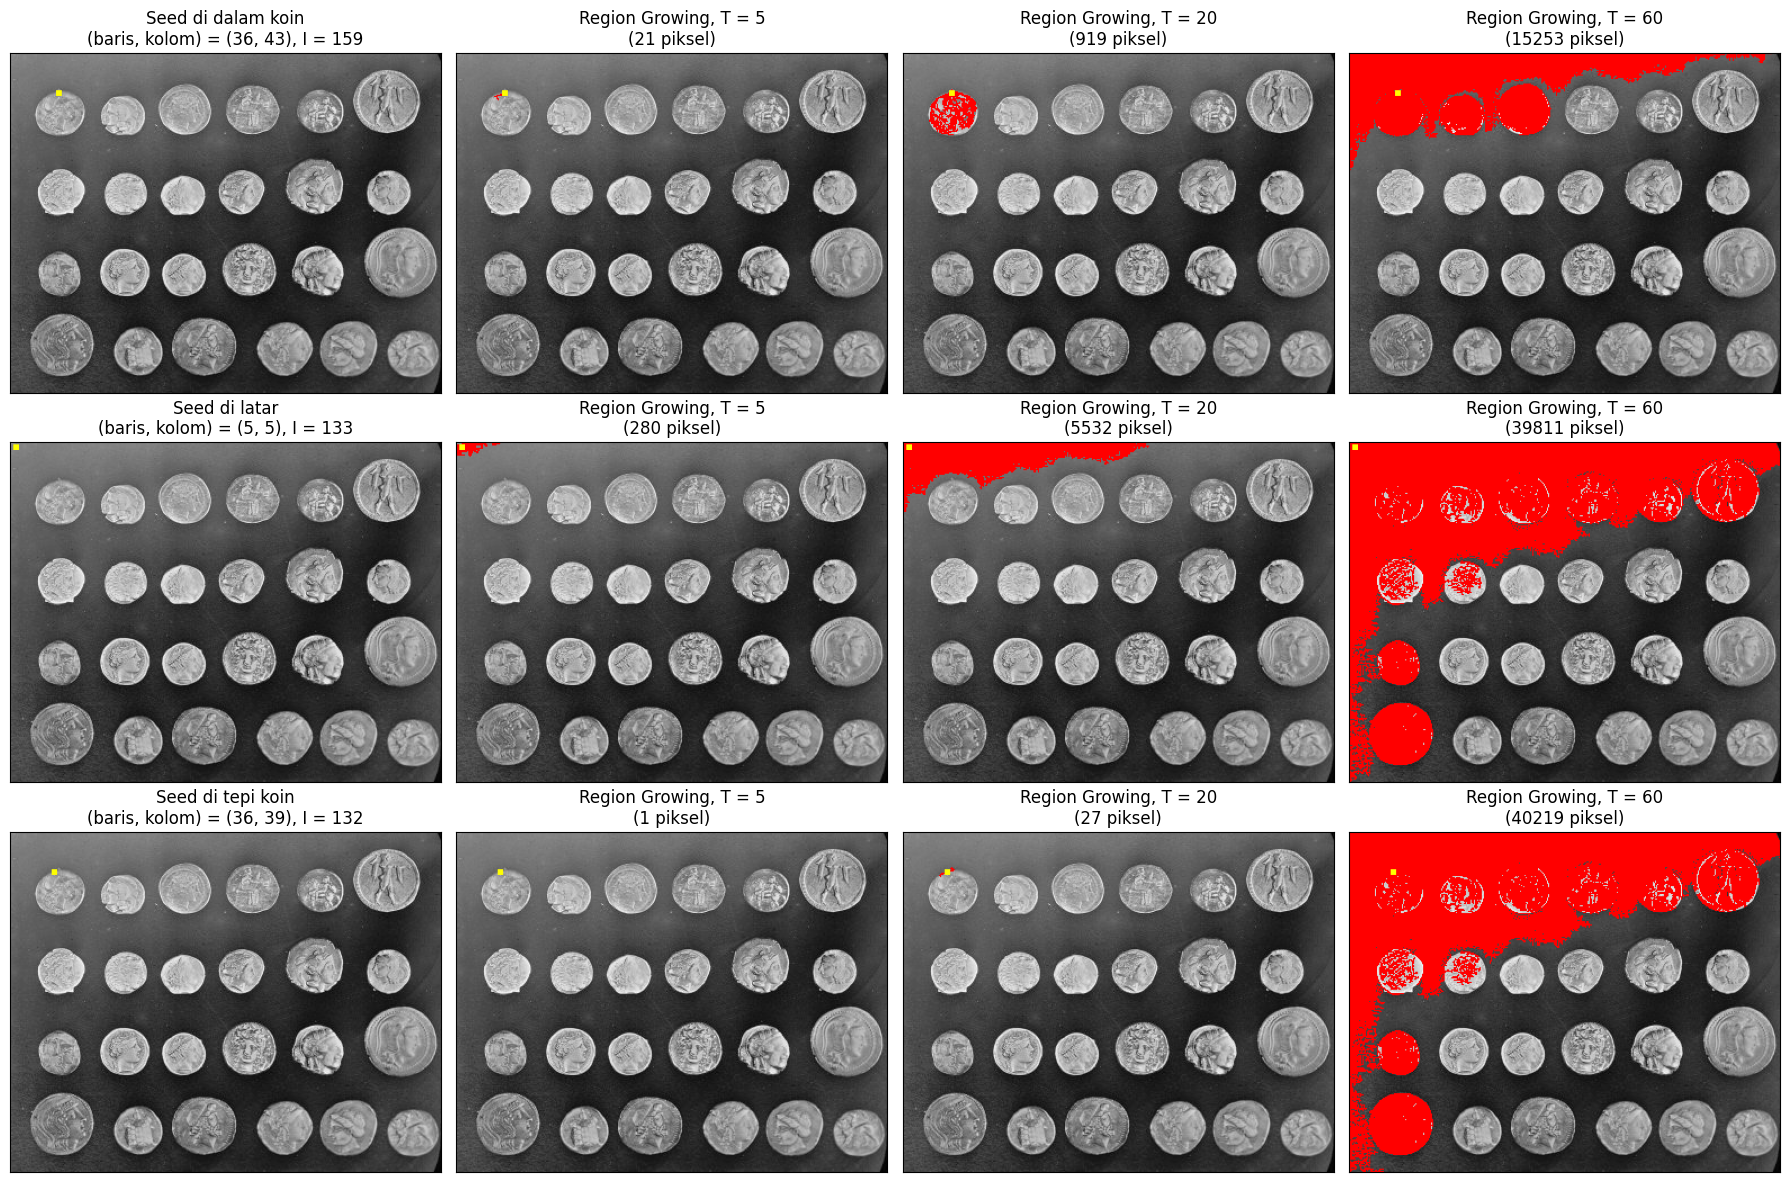

In [20]:
gray = data.coins()          # grayscale, 303 x 384
print("Ukuran citra:", gray.shape)

def region_growing(gray, seed, T):
    H, W = gray.shape
    ref = int(gray[seed])                         # intensitas seed sebagai acuan
    mask = np.zeros((H, W), dtype=bool)
    mask[seed] = True
    antrian = deque([seed])
    while antrian:
        y, x = antrian.popleft()
        for dy, dx in ((-1, 0), (1, 0), (0, -1), (0, 1)):      # 4 tetangga
            ny, nx = y + dy, x + dx
            if 0 <= ny < H and 0 <= nx < W and not mask[ny, nx]:
                if abs(int(gray[ny, nx]) - ref) <= T:
                    mask[ny, nx] = True
                    antrian.append((ny, nx))
    return mask

def overlay(gray, mask, seed):
    rgb = np.stack([gray] * 3, axis=-1).copy()
    rgb[mask] = [255, 0, 0]                                     # region = merah
    y, x = seed
    rgb[max(y-2, 0):y+3, max(x-2, 0):x+3] = [255, 255, 0]       # seed = kuning
    return rgb

SEEDS = {
    'Seed di dalam koin': (36, 43),
    'Seed di latar'     : (5, 5),
    'Seed di tepi koin' : (36, 39),
}
T_LIST = [5, 20, 60]

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
manual_count = {}
for r, (nama, seed) in enumerate(SEEDS.items()):
    axes[r, 0].imshow(overlay(gray, np.zeros_like(gray, dtype=bool), seed))
    axes[r, 0].set_title(f"{nama}\n(baris, kolom) = {seed}, I = {gray[seed]}")
    for c, T in enumerate(T_LIST):
        m = region_growing(gray, seed, T)
        manual_count[(nama, T)] = int(m.sum())
        print(f"{nama:20s} T = {T:2d} -> {m.sum():6d} piksel")
        axes[r, c+1].imshow(overlay(gray, m, seed))
        axes[r, c+1].set_title(f"Region Growing, T = {T}\n({m.sum()} piksel)")
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

Seed di dalam koin   T =  5: flood =     21 piksel | manual =     21 | identik: True
Seed di dalam koin   T = 20: flood =    919 piksel | manual =    919 | identik: True
Seed di dalam koin   T = 60: flood =  15253 piksel | manual =  15253 | identik: True
Seed di latar        T =  5: flood =    280 piksel | manual =    280 | identik: True
Seed di latar        T = 20: flood =   5532 piksel | manual =   5532 | identik: True
Seed di latar        T = 60: flood =  39811 piksel | manual =  39811 | identik: True
Seed di tepi koin    T =  5: flood =      1 piksel | manual =      1 | identik: True
Seed di tepi koin    T = 20: flood =     27 piksel | manual =     27 | identik: True
Seed di tepi koin    T = 60: flood =  40219 piksel | manual =  40219 | identik: True


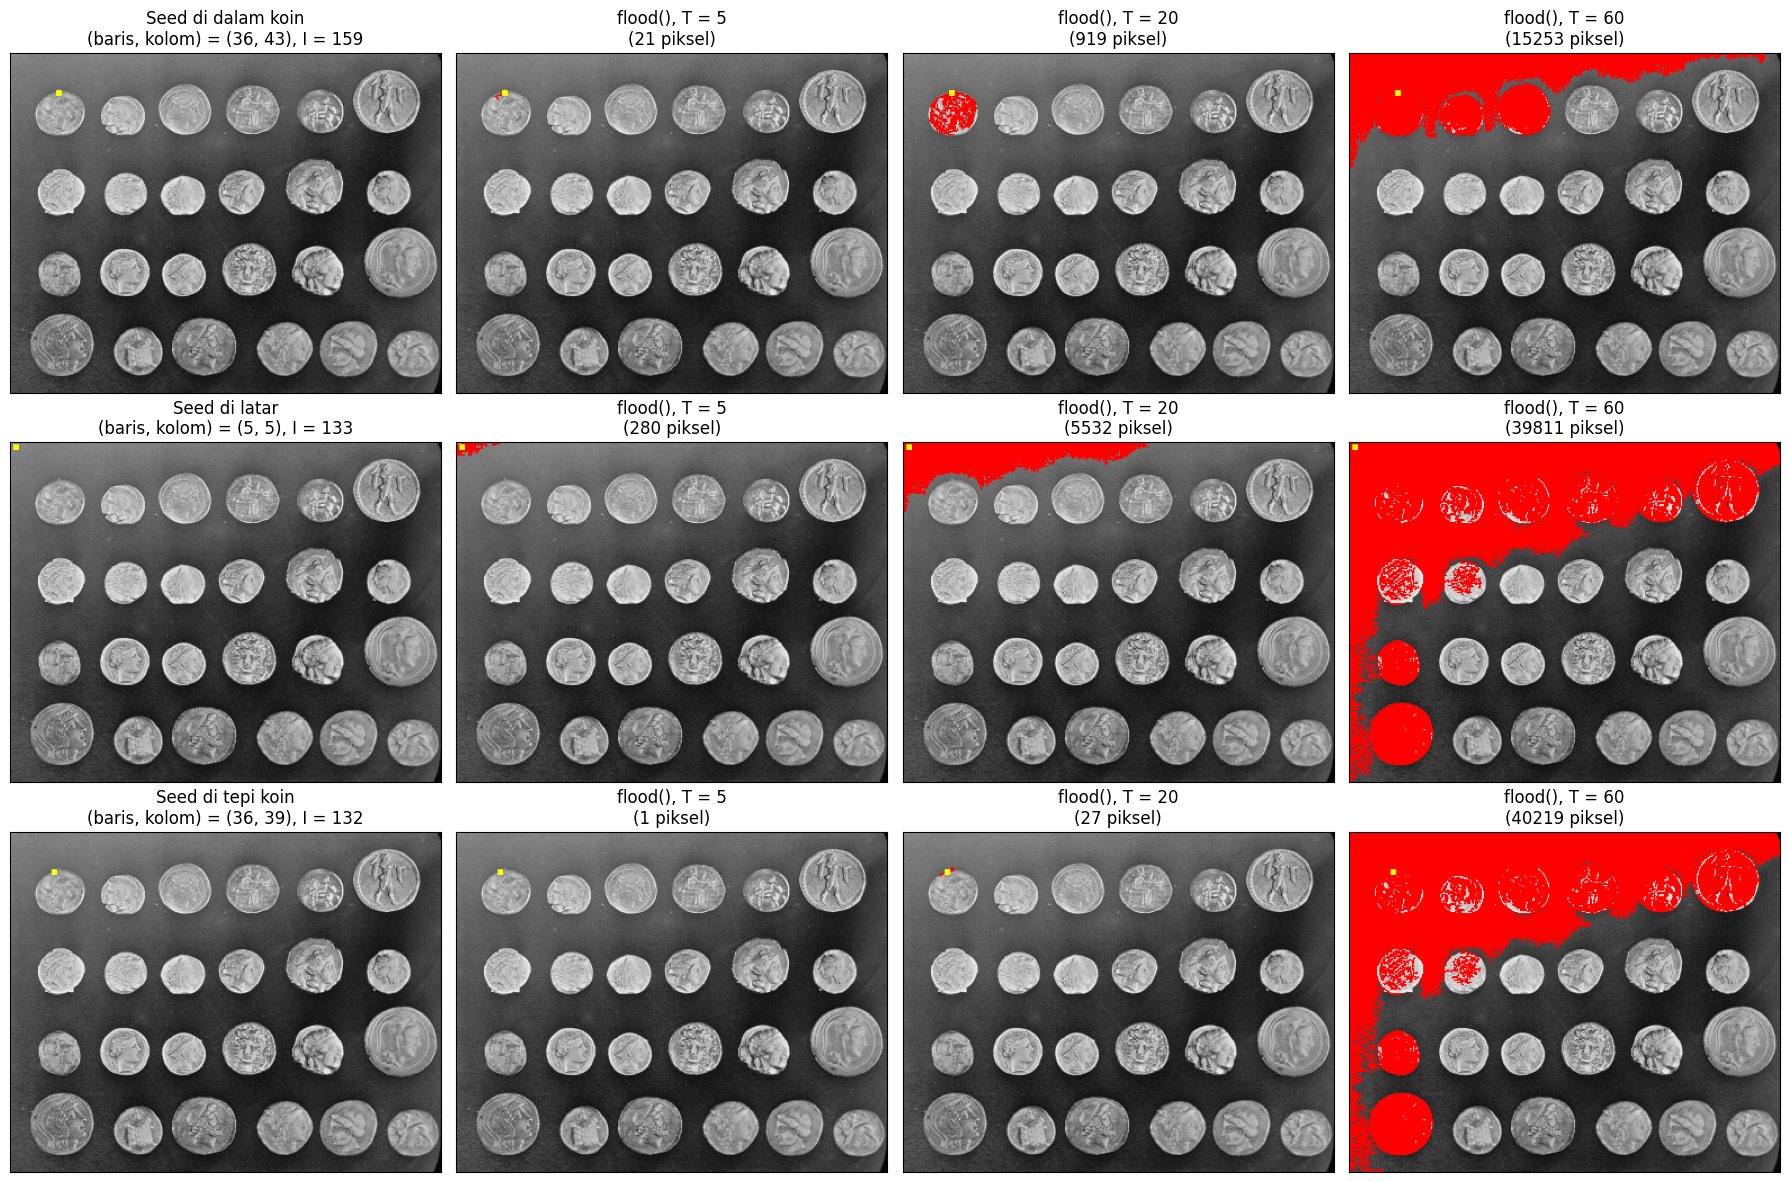

In [21]:
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
for r, (nama, seed) in enumerate(SEEDS.items()):
    axes[r, 0].imshow(overlay(gray, np.zeros_like(gray, dtype=bool), seed))
    axes[r, 0].set_title(f"{nama}\n(baris, kolom) = {seed}, I = {gray[seed]}")
    for c, T in enumerate(T_LIST):
        # Segmentasi menggunakan fungsi siap pakai
        region = flood(
            gray,
            seed_point=seed,
            tolerance=T,
            connectivity=1        # 4 tetangga untuk citra 2D
        )
        sama = np.array_equal(region, region_growing(gray, seed, T))
        print(f"{nama:20s} T = {T:2d}: flood = {region.sum():6d} piksel | "
              f"manual = {manual_count[(nama, T)]:6d} | identik: {sama}")
        axes[r, c+1].imshow(overlay(gray, region, seed))
        axes[r, c+1].set_title(f"flood(), T = {T}\n({region.sum()} piksel)")
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

> segmentasi warna pada image ktp_fulan

Pusat cluster (RGB): [[135, 147, 155], [218, 239, 248], [15, 16, 17], [215, 70, 51], [195, 224, 244], [239, 210, 172], [252, 254, 254], [59, 60, 63]]
Pusat cluster (HSV): [[102, 33, 155], [99, 31, 248], [105, 30, 17], [3, 195, 215], [102, 51, 244], [17, 71, 239], [90, 2, 254], [113, 16, 63]]
Cluster biru       : [0, 1, 4]


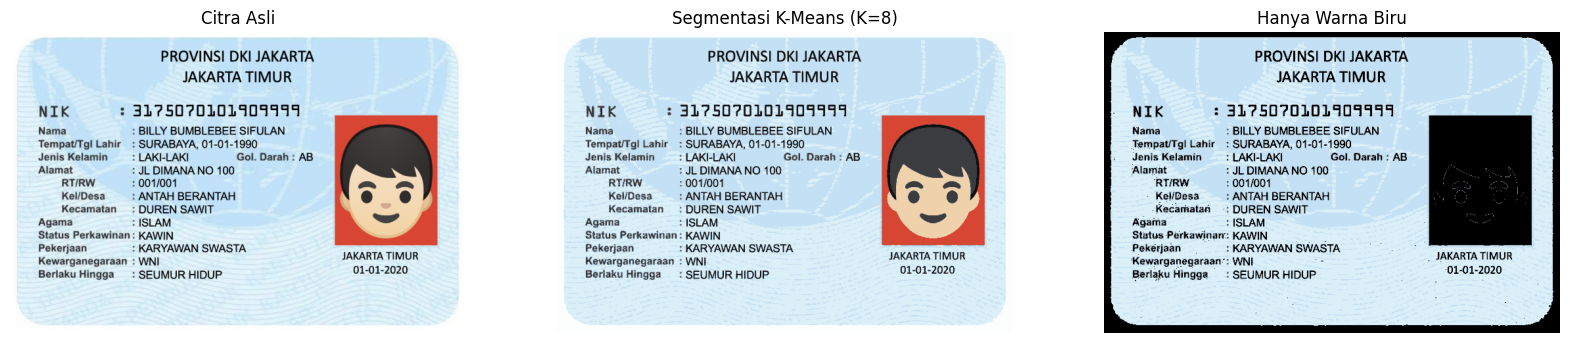

In [22]:
from sklearn.cluster import KMeans

filename = '/content/drive/MyDrive/PCVK/Images/ktp_fulan.jpg'
bgr = cv.imread(filename)
assert bgr is not None, f"File tidak ditemukan: {filename}"
rgb = cv.cvtColor(bgr, cv.COLOR_BGR2RGB)

# K-Means pada piksel RGB
Z = np.float32(rgb.reshape((-1, 3)))
K = 8
rng = np.random.default_rng(42)
sampel = Z[rng.choice(len(Z), size=min(len(Z), 50000), replace=False)]   # fit di sampel agar cepat
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10).fit(sampel)
labels = kmeans.predict(Z)                      # label untuk semua piksel
centers = np.uint8(kmeans.cluster_centers_)

segmented_img = centers[labels].reshape(rgb.shape)

# Cluster mana yang berwarna biru? Cek pusat cluster di ruang HSV (H skala OpenCV 0-179)
hsv_centers = cv.cvtColor(centers.reshape(1, -1, 3), cv.COLOR_RGB2HSV).reshape(-1, 3).astype(int)
H, S, V = hsv_centers[:, 0], hsv_centers[:, 1], hsv_centers[:, 2]
kelompok_biru = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))[0]

print("Pusat cluster (RGB):", centers.tolist())
print("Pusat cluster (HSV):", hsv_centers.tolist())
print("Cluster biru       :", kelompok_biru.tolist())

# Tampilkan hanya piksel dari cluster biru
mask_biru = np.isin(labels, kelompok_biru).reshape(rgb.shape[:2])
hanya_biru = np.zeros_like(rgb)
hanya_biru[mask_biru] = segmented_img[mask_biru]

titles = ['Citra Asli', f'Segmentasi K-Means (K={K})', 'Hanya Warna Biru']
plt.figure(figsize=(20, 6))
for i, im in enumerate([rgb, segmented_img, hanya_biru]):
    plt.subplot(1, 3, i+1)
    plt.imshow(im)
    plt.title(titles[i])
    plt.axis('off')
plt.show()

# **Tugas Kelompok**

In [40]:
# ===== SEL IDENTITAS KELOMPOK =====
NAMA = 'Nurfinka Lailasari'
NIM = '244107020211'

ANGGOTA_KELOMPOK = [
    {'nama': 'Mohammad Al Hafis Hidayatulloh', 'nim': '254107023005', 'file': 'ktm_hafis.jpg'},
    {'nama': 'Radit Firansah',                 'nim': '244107020196', 'file': 'ktm_radit.jpeg'},
    {'nama': 'Muhammad Rayhan Zamzami',        'nim': '244107020027', 'file': 'ktm_rayhan.jpeg'},
    {'nama': 'Nurfinka Lailasari',             'nim': '244107020211', 'file': 'ktm_nurfinka.jpeg'}
]

print("=" * 65)
print("PRAKTIKUM 7: SEGMENTASI CITRA DENGAN THRESHOLDING & OCR")
print(f"Koordinator / Pengunggah: {NAMA} (NIM: {NIM})")
print("-" * 65)
print("Daftar Anggota Kelompok:")
for i, ag in enumerate(ANGGOTA_KELOMPOK, 1):
    print(f"  {i}. {ag['nama']:32s} | NIM: {ag['nim']}")
print("=" * 65)

PRAKTIKUM 7: SEGMENTASI CITRA DENGAN THRESHOLDING & OCR
Koordinator / Pengunggah: Nurfinka Lailasari (NIM: 244107020211)
-----------------------------------------------------------------
Daftar Anggota Kelompok:
  1. Mohammad Al Hafis Hidayatulloh   | NIM: 254107023005
  2. Radit Firansah                   | NIM: 244107020196
  3. Muhammad Rayhan Zamzami          | NIM: 244107020027
  4. Nurfinka Lailasari               | NIM: 244107020211


In [41]:
# 1. Mount Google Drive & Deteksi Folder Dataset
import os
import glob

FOLDER = None
try:
    from google.colab import drive
    drive.mount('/content/drive')

    # Lokasi folder dataset di Google Drive (case-sensitive di Colab)
    kandidat_colab = [
        '/content/drive/My Drive/PCVK/Images/KTM KELOMPOK',
        '/content/drive/My Drive/PCVK/Images',
    ]
    for k in kandidat_colab:
        if os.path.exists(k):
            FOLDER = k
            break

    # Jika belum ketemu, cari otomatis folder 'Images' di dalam folder 'PCVK'
    if FOLDER is None:
        for root, dirs, _ in os.walk('/content/drive/MyDrive'):
            if os.path.basename(root).lower() == 'pcvk' and 'Images' in dirs:
                FOLDER = os.path.join(root, 'Images')
                break
except Exception:
    pass

# Fallback jika dijalankan di lingkungan lokal / desktop
if FOLDER is None:
    kandidat_lokal = [
        os.path.join(os.getcwd(), 'Images'),
        os.path.join(os.getcwd(), 'PCVK', 'Images'),
        'Images',
    ]
    for k in kandidat_lokal:
        if os.path.exists(k):
            FOLDER = k
            break

if FOLDER is None:
    FOLDER = os.path.join(os.getcwd(), 'Images')

print("Direktori dataset praktikum:", FOLDER)
if not os.path.exists(FOLDER):
    print("PERINGATAN: Folder dataset belum ditemukan! Pastikan folder 'PCVK/Images' ada di Google Drive.")
else:
    print(f"Status: Folder ditemukan dengan {len(os.listdir(FOLDER))} item.")
    print("Isi folder:", sorted(os.listdir(FOLDER)))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Direktori dataset praktikum: /content/drive/My Drive/PCVK/Images/KTM KELOMPOK
Status: Folder ditemukan dengan 4 item.
Isi folder: ['ktm_hafis.jpeg', 'ktm_nurfinka.jpeg', 'ktm_radit.jpeg', 'ktm_rayhan.jpeg']


## **Uji Coba pada Citra KTM Sendiri (`ktm_nurfinka.jpg`)**

In [42]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

# Ganti dengan NIM kamu kalau belum didefinisikan di cell sebelumnya
try:
    NIM
except NameError:
    NIM = '244107020211'

def otsu_manual(img):
    """Hitung threshold Otsu dari nol dengan memaksimalkan varians antar-kelas."""
    hist = np.bincount(img.ravel(), minlength=256).astype(np.float64)
    prob = hist / hist.sum()
    omega = np.cumsum(prob)                      # probabilitas kumulatif kelas 0
    mu = np.cumsum(prob * np.arange(256))        # rata-rata kumulatif
    mu_t = mu[-1]
    with np.errstate(divide='ignore', invalid='ignore'):
        sigma_b2 = (mu_t * omega - mu) ** 2 / (omega * (1.0 - omega))
    sigma_b2 = np.nan_to_num(sigma_b2)
    return int(np.argmax(sigma_b2))

def evaluasi_otsu(img, judul, ksize=(5, 5)):
    """
    Bandingkan threshold Otsu manual vs OpenCV pada citra grayscale.
    Mengembalikan: (citra_blur, threshold_manual, threshold_library)
    """
    if img is None:
        raise ValueError("Citra kosong (None). Periksa path file dan hasil cv.imread.")

    blur = cv.GaussianBlur(img, ksize, 0)

    t_manual = otsu_manual(blur)
    t_lib, bin_lib = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    t_lib = int(t_lib)
    bin_manual = np.where(blur > t_manual, 255, 0).astype(np.uint8)

    print(f"[{judul}]")
    print(f"  Threshold Otsu manual  : {t_manual}")
    print(f"  Threshold Otsu library : {t_lib}")
    print(f"  Selisih                : {abs(t_manual - t_lib)}")

    fig, ax = plt.subplots(1, 4, figsize=(18, 4))
    ax[0].imshow(img, cmap='gray', vmin=0, vmax=255)
    ax[0].set_title('Grayscale asli')
    ax[1].imshow(blur, cmap='gray', vmin=0, vmax=255)
    ax[1].set_title(f'Gaussian blur {ksize}')
    ax[2].imshow(bin_manual, cmap='gray')
    ax[2].set_title(f'Otsu manual (T={t_manual})')
    ax[3].imshow(bin_lib, cmap='gray')
    ax[3].set_title(f'Otsu OpenCV (T={t_lib})')
    for a in ax:
        a.axis('off')
    fig.suptitle(judul)
    plt.tight_layout()
    plt.show()

    return blur, t_manual, t_lib

[KTM Nurfinka (NIM: 244107020211)]
  Threshold Otsu manual  : 123
  Threshold Otsu library : 123
  Selisih                : 0


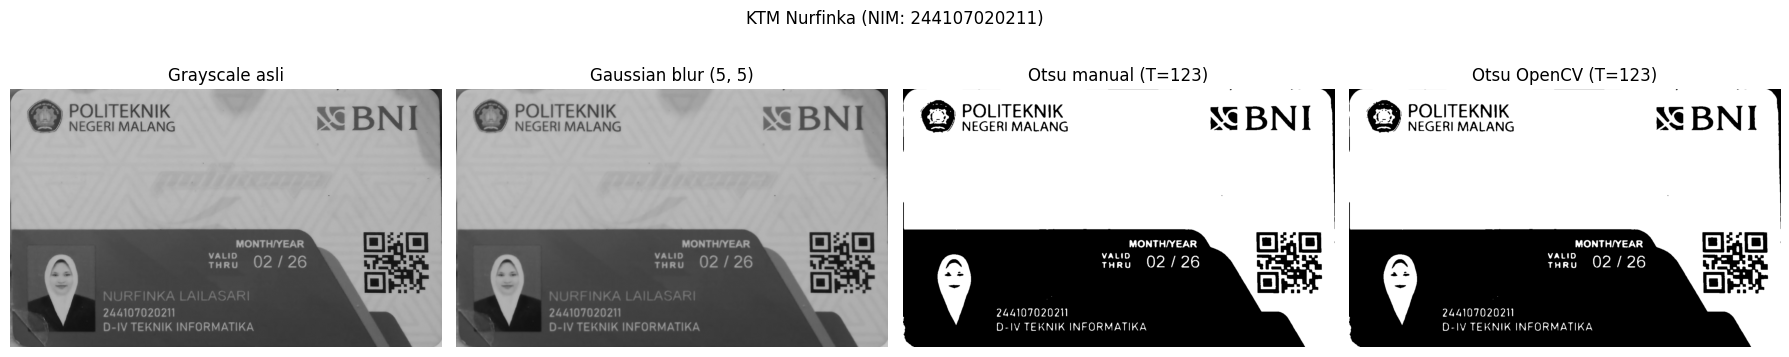

In [43]:
# Membaca citra KTM Nurfinka
path_ktm_nurfinka = cari_file('ktm_nurfinka')
img_ktm_nurfinka = cv.imread(path_ktm_nurfinka, cv.IMREAD_GRAYSCALE)

blur_ktm, t_otsu_ktm, t_lib_ktm = evaluasi_otsu(img_ktm_nurfinka, f"KTM Nurfinka (NIM: {NIM})")

In [44]:
# Instalasi Tesseract OCR dan paket bahasa Indonesia di lingkungan Colab
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract tabulate

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [45]:
# Import Library OCR dan Definisi Data Anggota Kelompok
import pytesseract
import pandas as pd
from tabulate import tabulate

CONFIG_OCR = '--psm 3'
LANG_OCR = 'ind'
CONF_MIN = 60
LEBAR_STANDAR = 1000
BLOCK_ADAPTIVE = 31
C_ADAPTIVE = 10

# 10 kata/angka acuan faktual yang tertera pada kartu KTM masing-masing anggota
DATA_KTM_ANGGOTA = {
    'hafis': {
        'nama_lengkap': 'Mohammad Al Hafis Hidayatulloh',
        'nim': '254107023005',
        'file_ktm': 'ktm_hafis',
        'acuan': ['POLITEKNIK', 'NEGERI', 'MALANG', 'BNI', 'MOHAMMAD', 'HAFIS', 'HIDAYATULLOH', '254107023005', 'TEKNIK', 'INFORMATIKA']
    },
    'radit': {
        'nama_lengkap': 'Radit Firansah',
        'nim': '244107020196',
        'file_ktm': 'ktm_radit',
        'acuan': ['POLITEKNIK', 'NEGERI', 'MALANG', 'BNI', 'RADIT', 'FIRANSAH', '244107020196', 'D-IV', 'TEKNIK', 'INFORMATIKA']
    },
    'rayhan': {
        'nama_lengkap': 'Muhammad Rayhan Zamzami',
        'nim': '244107020027',
        'file_ktm': 'ktm_rayhan',
        'acuan': ['POLITEKNIK', 'NEGERI', 'MALANG', 'BNI', 'MUHAMMAD', 'RAYHAN', 'ZAMZAMI', '244107020027', 'TEKNIK', 'INFORMATIKA']
    },
    'nurfinka': {
        'nama_lengkap': 'Nurfinka Lailasari',
        'nim': '244107020211',
        'file_ktm': 'ktm_nurfinka',
        'acuan': ['POLITEKNIK', 'NEGERI', 'MALANG', 'BNI', 'NURFINKA', 'LAILASARI', '244107020211', 'D-IV', 'TEKNIK', 'INFORMATIKA']
    }
}

print("Konfigurasi OCR:")
print(f"  - Bahasa      : {LANG_OCR}")
print(f"  - PSM config  : {CONFIG_OCR}")
print(f"  - Lebar citra : {LEBAR_STANDAR} px")
print(f"  - Min Conf    : {CONF_MIN}%")

Konfigurasi OCR:
  - Bahasa      : ind
  - PSM config  : --psm 3
  - Lebar citra : 1000 px
  - Min Conf    : 60%


### 1. Menyiapkan Tiga Citra untuk Dibandingkan
Untuk setiap KTM, disiapkan 3 citra masukan dengan resolusi lebar yang seragam ($1000$ piksel):
1. **Berwarna Asli**
2. **Segmentasi Otsu**
3. **Segmentasi Adaptive** (Gaussian $31 \times 31, C = 10$)

In [46]:
import inspect
print(inspect.getsource(cari_file))
print("FOLDER:", FOLDER)

def cari_file(nama, folder=None):
    """Cari file citra berdasarkan nama (rekursif, tidak peka format penulisan)."""
    folder = folder or FOLDER
    ekstensi = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')
    target = _normal(nama)
    kandidat = []
    for root, dirs, files in os.walk(folder):
        for f in files:
            if f.lower().endswith(ekstensi):
                kandidat.append(os.path.join(root, f))
                if target in _normal(os.path.splitext(f)[0]):
                    return os.path.join(root, f)
    raise FileNotFoundError(
        f"'{nama}' tidak ditemukan di {folder}. File citra yang ada: {kandidat}"
    )

FOLDER: /content/drive/My Drive/PCVK/Images/KTM KELOMPOK


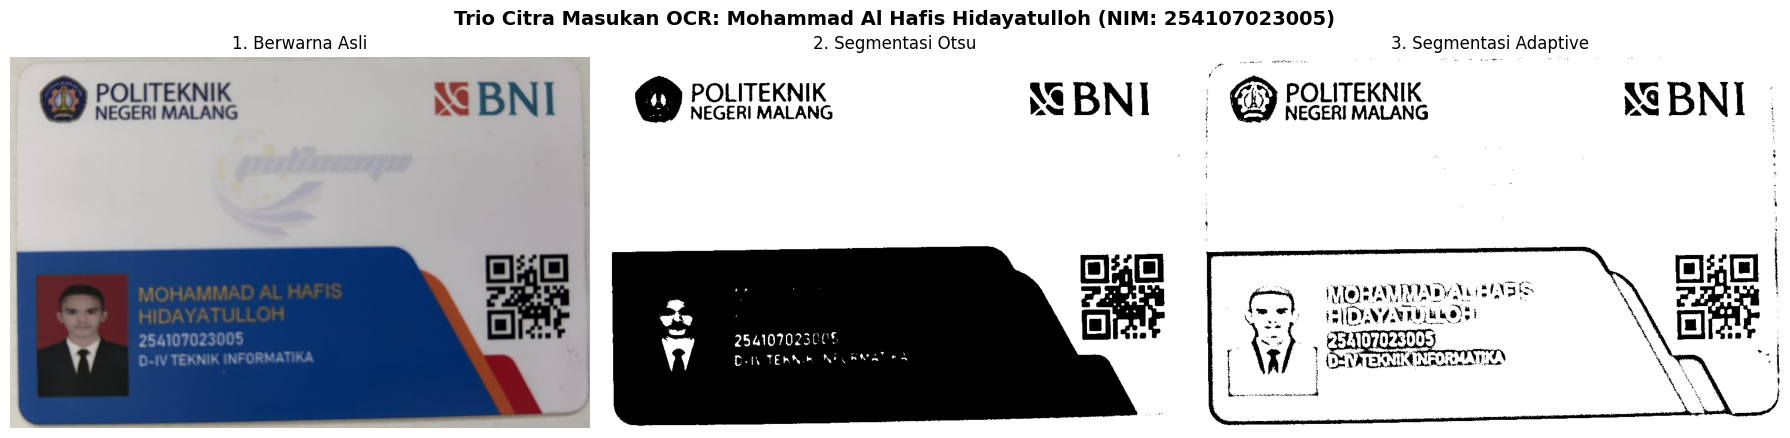

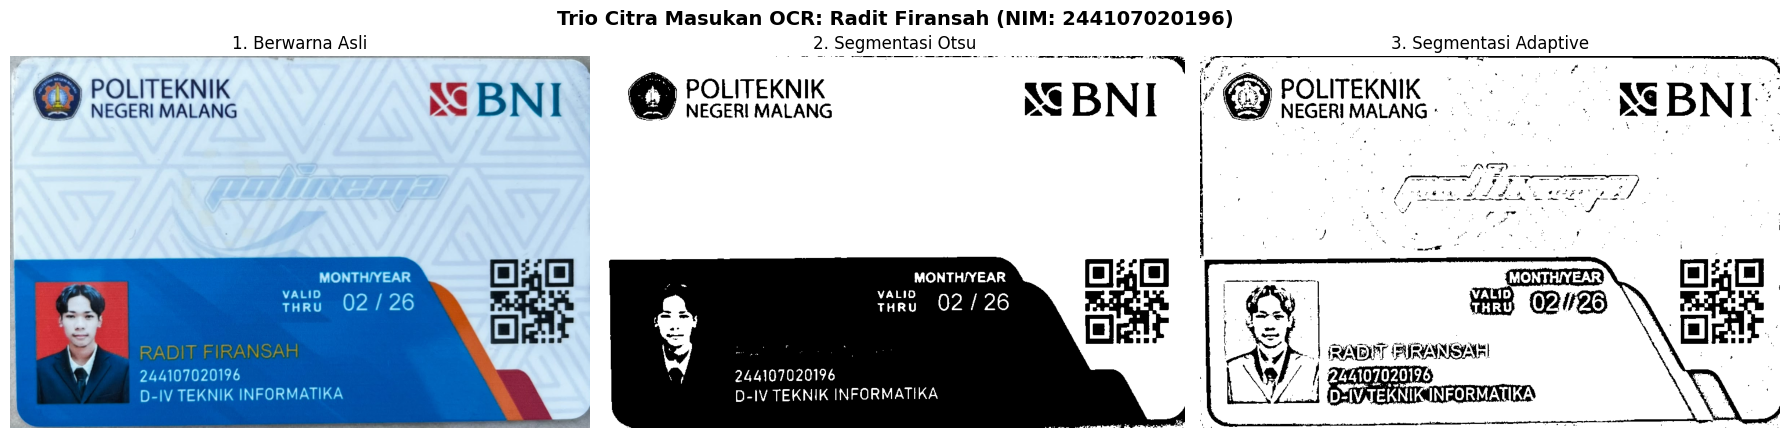

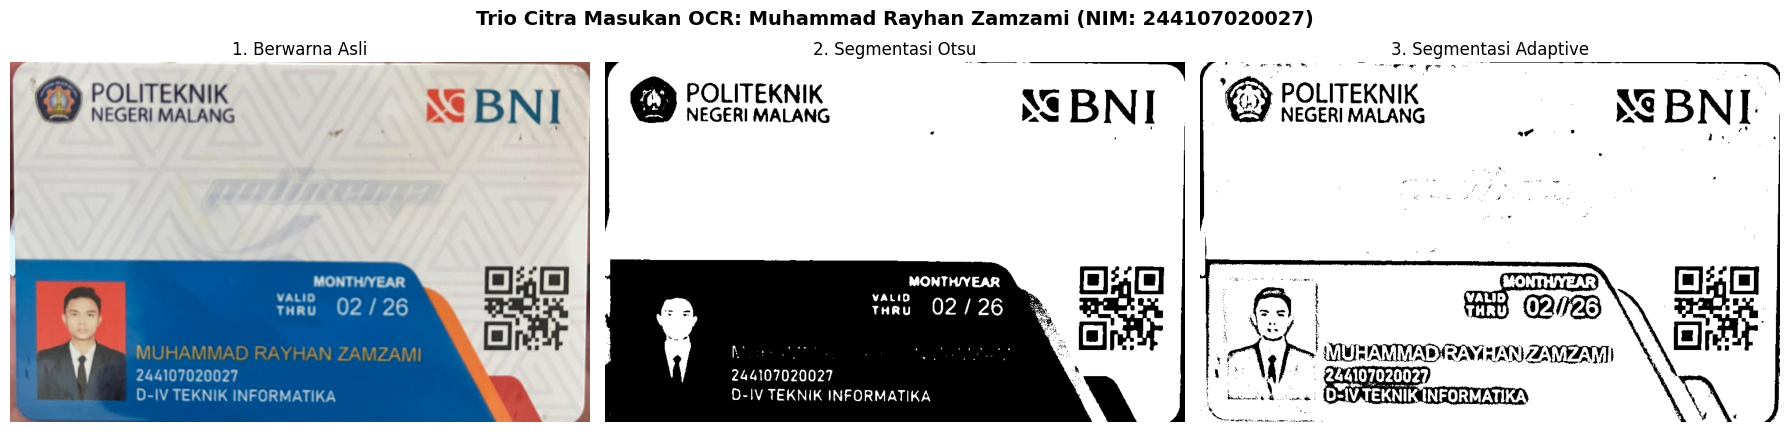

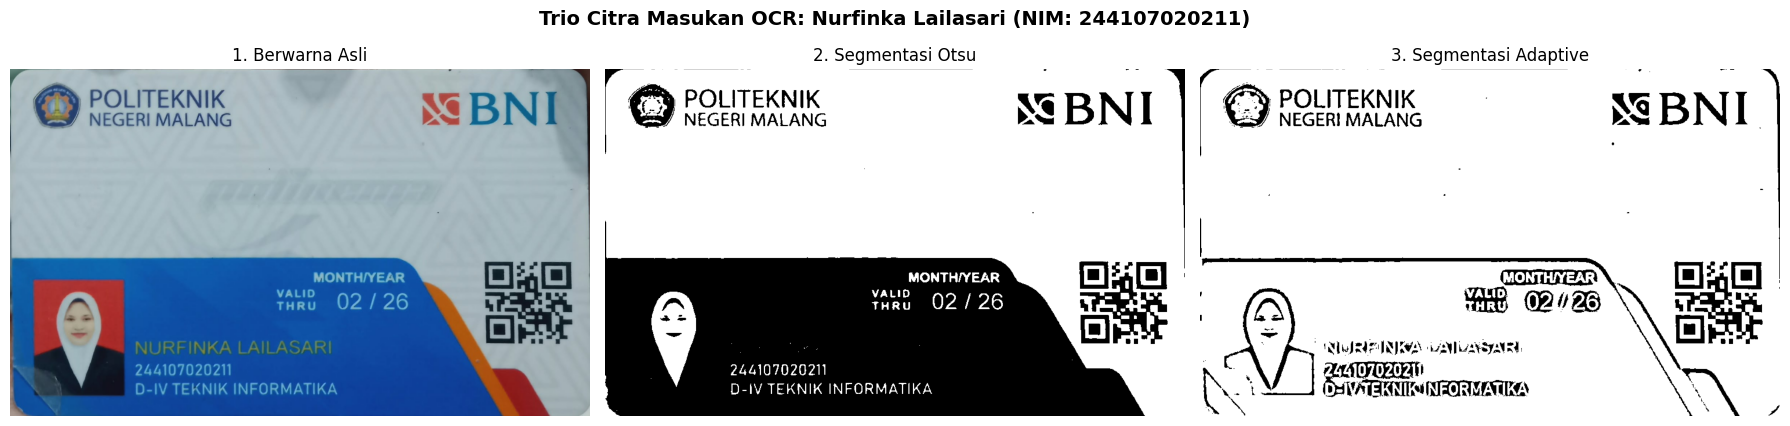

In [54]:
import re
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

def tampil_grid(images, titles, baris=1, kolom=3, ukuran=(18, 4.5), judul_utama=""):
    """Fungsi pembantu untuk menampilkan beberapa gambar dalam satu baris."""
    fig, axes = plt.subplots(baris, kolom, figsize=ukuran)
    axes = np.array(axes).ravel()
    for i, (img, title) in enumerate(zip(images, titles)):
        if i < len(axes):
            if img.ndim == 3:
                axes[i].imshow(img)
            else:
                axes[i].imshow(img, cmap='gray')
            axes[i].set_title(title)
            axes[i].axis('off')
    fig.suptitle(judul_utama, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

def siapkan_trio_citra(awalan_file):
    """Membaca KTM, menyeragamkan ukuran ke lebar 1000 px, dan menghasilkan 3 citra uji."""
    # Lakukan pencarian file menggunakan fungsi cari_file secara rekursif
    path_gambar = cari_file(awalan_file)
    bgr = cv.imread(path_gambar)
    if bgr is None:
        raise ValueError(f"Gagal membaca gambar dari path: {path_gambar}")

    h, w = bgr.shape[:2]
    # Resize menjaga aspect ratio
    bgr_resized = cv.resize(bgr, (LEBAR_STANDAR, int(h * LEBAR_STANDAR / w)))
    gray = cv.cvtColor(bgr_resized, cv.COLOR_BGR2GRAY)

    # 1. Otsu Thresholding
    _, otsu_thresh = cv.threshold(gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

    # 2. Adaptive Gaussian Thresholding
    adaptive_thresh = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                           cv.THRESH_BINARY, BLOCK_ADAPTIVE, C_ADAPTIVE)

    return {
        'BERWARNA': cv.cvtColor(bgr_resized, cv.COLOR_BGR2RGB),
        'OTSU': otsu_thresh,
        'ADAPTIVE': adaptive_thresh
    }

# Siapkan trio citra untuk seluruh 4 anggota kelompok
citra_kelompok = {}
for id_anggota, data_ag in DATA_KTM_ANGGOTA.items():
    try:
        citra_kelompok[id_anggota] = siapkan_trio_citra(data_ag['file_ktm'])
    except Exception as e:
        print(f"Gagal memproses KTM untuk {id_anggota}: {e}")

# Tampilkan visualisasi 3 citra untuk masing-masing anggota yang sukses diproses
for id_anggota, data_ag in DATA_KTM_ANGGOTA.items():
    if id_anggota in citra_kelompok:
        trio = citra_kelompok[id_anggota]
        tampil_grid([trio['BERWARNA'], trio['OTSU'], trio['ADAPTIVE']],
                    ['1. Berwarna Asli', '2. Segmentasi Otsu', '3. Segmentasi Adaptive'],
                    baris=1, kolom=3, ukuran=(18, 4.5),
                    judul_utama=f"Trio Citra Masukan OCR: {data_ag['nama_lengkap']} (NIM: {data_ag['nim']})")

### 2. Pembacaan Teks Menggunakan `pytesseract.image_to_string()`
Membaca teks secara lengkap pada ketiga varian citra untuk masing-masing anggota kelompok menggunakan konfigurasi bahasa dan PSM yang seragam.

In [49]:
# Eksekusi OCR image_to_string
teks_ocr = {}

for id_anggota, data_ag in DATA_KTM_ANGGOTA.items():
    teks_ocr[id_anggota] = {}
    print("=" * 70)
    print(f"HASIL OCR TEKS LENGKAP: {data_ag['nama_lengkap'].upper()} ({data_ag['nim']})")
    print("=" * 70)

    for jenis_citra in ['BERWARNA', 'OTSU', 'ADAPTIVE']:
        citra_input = citra_kelompok[id_anggota][jenis_citra]
        # Jika citra biner (grayscale 2D), Tesseract langsung memprosesnya
        raw_text = pytesseract.image_to_string(citra_input, lang=LANG_OCR, config=CONFIG_OCR)
        teks_ocr[id_anggota][jenis_citra] = raw_text.strip()

        print(f"--- [{jenis_citra}] ---")
        teks_tampil = raw_text.strip() if raw_text.strip() else "(TIDAK ADA TEKS TERDETEKSI)"
        print(teks_tampil)
        print()

HASIL OCR TEKS LENGKAP: MOHAMMAD AL HAFIS HIDAYATULLOH (254107023005)
--- [BERWARNA] ---
POT BNI
MOHAMMAD /

HIDAY

254107023005
D-IV TEKNIK INFORMATIKA

--- [OTSU] ---
MERE MALANG Ae BNI

st

Sa 254107023005
DAN TEKAN NEKAT IA

--- [ADAPTIVE] ---
OA S$BNI

MOHAMMALAGE AFIS
Pua YATULLOHI

HASIL OCR TEKS LENGKAP: RADIT FIRANSAH (244107020196)
--- [BERWARNA] ---
y POLITEKNIK —
| AM PAN Ea NG BN I

--- [OTSU] ---
3 POLITEKNIK
8) NEGERI MALANG NC BNI

MONTH/YEAR

Haku 02/26

244107020196
D-IV TEKNIK INFORMATIKA

--- [ADAPTIVE] ---
Ty POLI uan | 3
G9 PELTEKNIK Da, xg BNI

RAD AANGAN

244107020126
#EDTIVTEKNIK INEORMATIKAY

HASIL OCR TEKS LENGKAP: MUHAMMAD RAYHAN ZAMZAMI (244107020027)
--- [BERWARNA] ---
| POLITEKNIK
NEGERI MALANG

MONTH/YEAR

turu 02/26

MUHAMMAD RAYHAN ZAMZAMI
244107020027
D-IV TEKNIK INFORMATIKA

--- [OTSU] ---
POLITEKNIK
NEGERI MALANG

@
w
Z
emang

Turu 02/26 '
244107020027

D-IV TEKNIK INFORMATIKA

--- [ADAPTIVE] ---
KO Ae ANK, Dea X BNI:

HASIL OCR TEKS LENGKAP: NURFIN

### 3. Visualisasi Area Teks dan Kotak Hijau (`pytesseract.image_to_data()`)
Mendeteksi posisi kata menggunakan `image_to_data()` dan menandai kata-kata yang memiliki nilai keyakinan (*confidence*) di atas batas ambang ($> 60$) dengan kotak hijau.

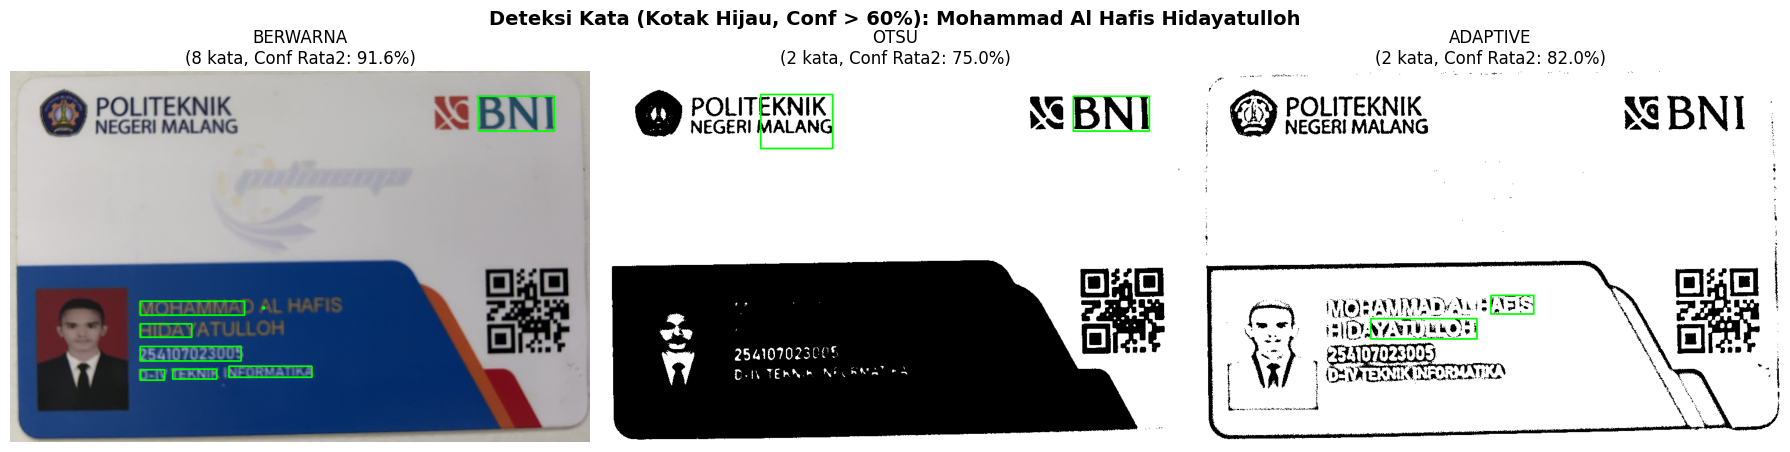

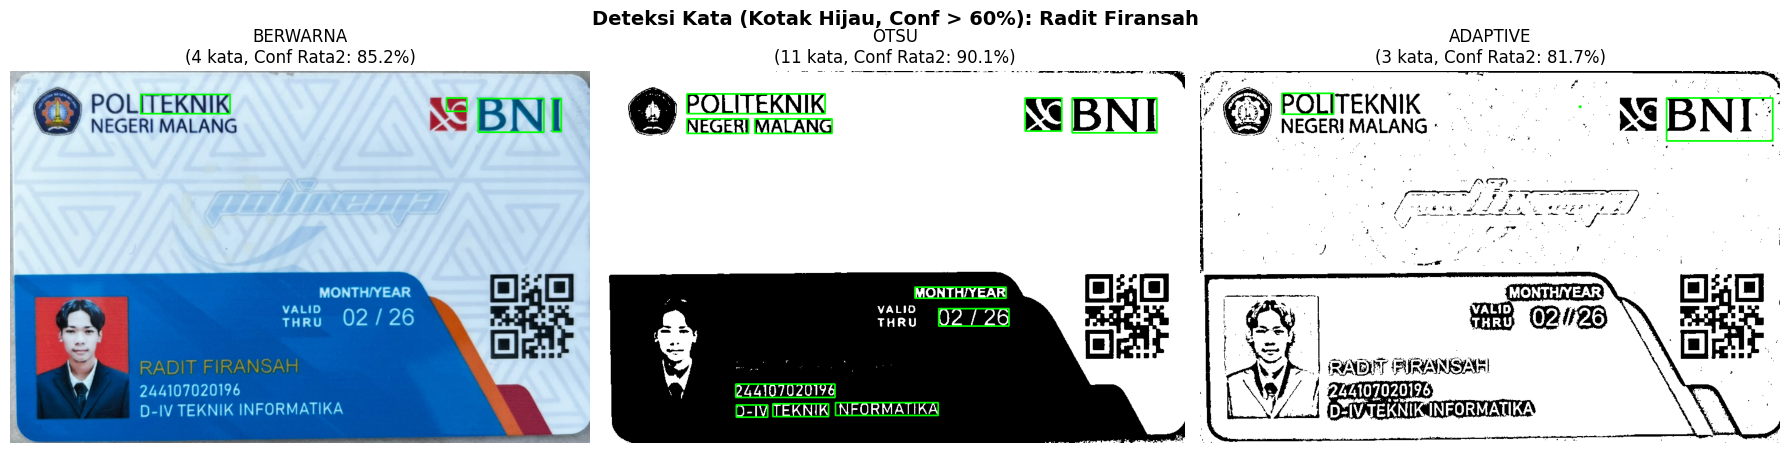

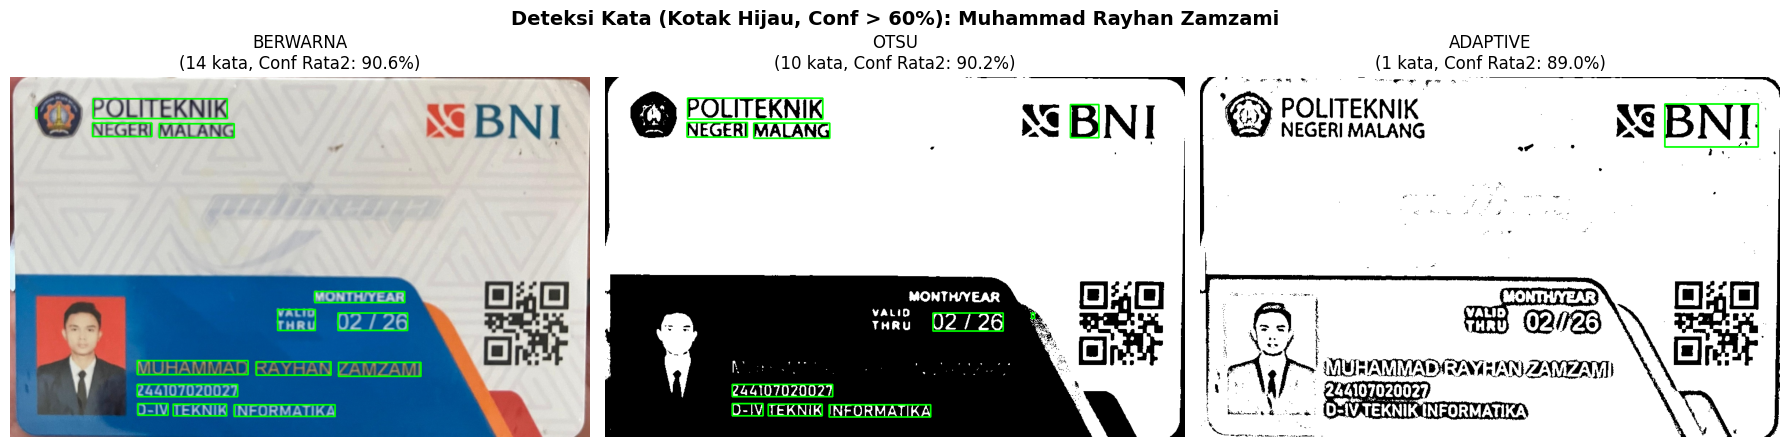

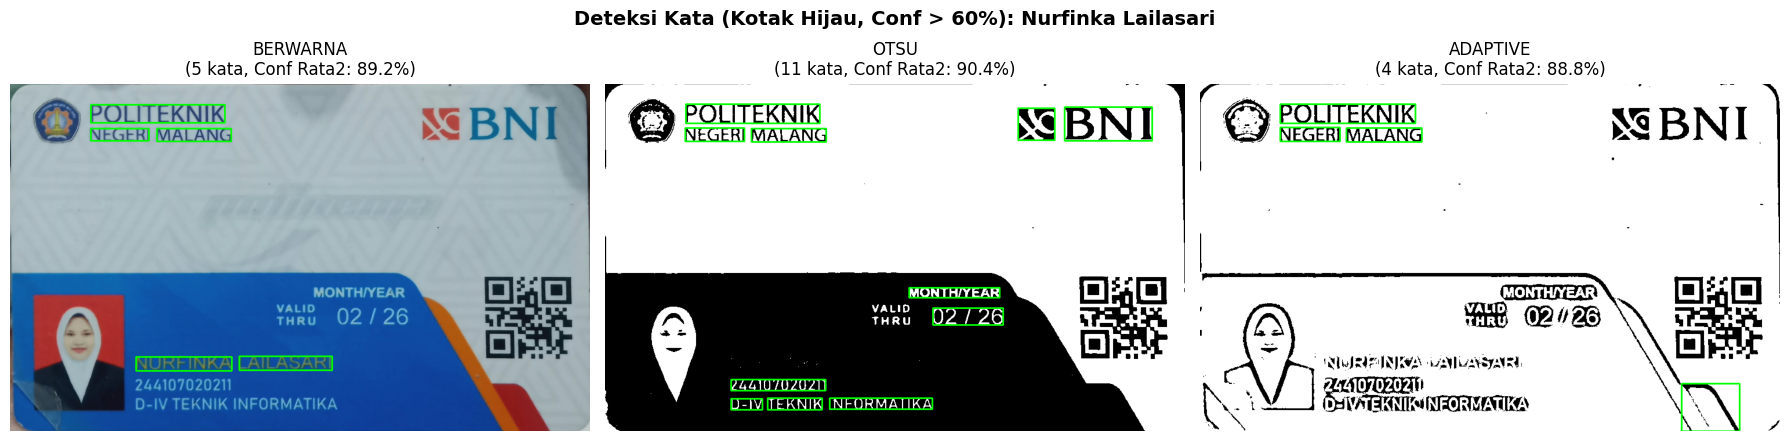

In [50]:
rata_rata_confidence = {}

for id_anggota, data_ag in DATA_KTM_ANGGOTA.items():
    rata_rata_confidence[id_anggota] = {}
    gambar_annotasi = []
    judul_annotasi  = []

    for jenis_citra in ['BERWARNA', 'OTSU', 'ADAPTIVE']:
        citra_input = citra_kelompok[id_anggota][jenis_citra]

        # Ekstraksi data bounding box dan confidence
        data_ocr = pytesseract.image_to_data(citra_input, lang=LANG_OCR, config=CONFIG_OCR,
                                             output_type=pytesseract.Output.DICT)

        # Buat kanvas berwarna untuk menggambar kotak hijau
        if citra_input.ndim == 2:
            kanvas = cv.cvtColor(citra_input, cv.COLOR_GRAY2RGB)
        else:
            kanvas = citra_input.copy()

        conf_valid = []
        n_kata = len(data_ocr['text'])

        for i in range(n_kata):
            conf_val = float(data_ocr['conf'][i])
            kata_teks = data_ocr['text'][i].strip()

            # Filter hanya kata non-kosong dengan confidence > CONF_MIN
            if conf_val > CONF_MIN and len(kata_teks) > 0:
                x = data_ocr['left'][i]
                y = data_ocr['top'][i]
                w = data_ocr['width'][i]
                h = data_ocr['height'][i]

                # Gambar persegi panjang hijau (0, 255, 0)
                cv.rectangle(kanvas, (x, y), (x + w, y + h), (0, 255, 0), 2)
                conf_valid.append(conf_val)

        rata_conf = np.mean(conf_valid) if len(conf_valid) > 0 else 0.0
        rata_rata_confidence[id_anggota][jenis_citra] = rata_conf

        gambar_annotasi.append(kanvas)
        judul_annotasi.append(f"{jenis_citra}\n({len(conf_valid)} kata, Conf Rata2: {rata_conf:.1f}%)")

    tampil_grid(gambar_annotasi, judul_annotasi, baris=1, kolom=3, ukuran=(18, 4.8),
                judul_utama=f"Deteksi Kata (Kotak Hijau, Conf > {CONF_MIN}%): {data_ag['nama_lengkap']}")

### 4. Evaluasi 10 Kata Acuan dan Tabel Perbandingan
Sesuai instruksi modul (Hal. 26 No. 4 & 5):
- Dilakukan evaluasi pada **10 kata atau angka acuan** yang terlihat jelas pada kartu.
- Penilaian dilakukan pada teks lengkap hasil OCR (`image_to_string`).
- **Aturan Pencocokan:** Hasil dinyatakan cocok ($\checkmark$) jika seluruh huruf atau angka sama dengan acuan (bersifat *case-insensitive*, mengabaikan spasi di awal/akhir dan tanda baca di sekeliling kata).
- Jika ada kesalahan pembacaan (typo/karakter salah), ditampilkan kata hasil OCR yang paling mendekati disertai tanda ($\boldsymbol{\times}$). Jika kata sama sekali tidak terdeteksi, ditampilkan `(tidak terbaca)` ($\boldsymbol{\times}$).

In [51]:
import difflib
import re

def evaluasi_kata_acuan(teks_lengkap, kata_acuan):
    """Mengecek apakah kata_acuan ditemukan dalam teks_lengkap hasil OCR."""
    # Pecah teks menjadi token kata dan bersihkan tanda baca di pinggir kata
    token_mentah = teks_lengkap.split()
    tokens = [re.sub(r'^[^a-zA-Z0-9]+|[^a-zA-Z0-9]+$', '', t) for t in token_mentah]
    tokens = [t for t in tokens if len(t) > 0]

    kata_acuan_clean = kata_acuan.strip()

    # 1. Cek Exact Match (Case-Insensitive)
    for t in tokens:
        if t.lower() == kata_acuan_clean.lower():
            return t, True

    # 2. Cek apakah ada token yang memuat kata acuan atau sebaliknya
    for t in tokens:
        if len(kata_acuan_clean) >= 4 and (kata_acuan_clean.lower() in t.lower() or t.lower() in kata_acuan_clean.lower()):
            if abs(len(t) - len(kata_acuan_clean)) <= 2:
                return t, (t.lower() == kata_acuan_clean.lower())

    # 3. Cari kata yang paling mendekati (Similarity Match)
    matches = difflib.get_close_matches(kata_acuan_clean, tokens, n=1, cutoff=0.45)
    if len(matches) > 0:
        return matches[0], False

    return "(tidak terbaca)", False

# Evaluasi 10 kata per anggota dan susun tabelnya
semua_tabel_detail = {}
ringkasan_hasil = []

for id_anggota, data_ag in DATA_KTM_ANGGOTA.items():
    baris_tabel = []
    skor_cocok = {'BERWARNA': 0, 'OTSU': 0, 'ADAPTIVE': 0}

    for no, item_acuan in enumerate(data_ag['acuan'], 1):
        data_baris = {'No.': no, 'Teks Sebenarnya': item_acuan}

        for jenis in ['BERWARNA', 'OTSU', 'ADAPTIVE']:
            teks_hasil = teks_ocr[id_anggota][jenis]
            kata_terbaca, is_cocok = evaluasi_kata_acuan(teks_hasil, item_acuan)

            simbol = "✓" if is_cocok else "✗"
            data_baris[f"OCR {jenis.title()}"] = f"{kata_terbaca} ({simbol})"
            if is_cocok:
                skor_cocok[jenis] += 1

        baris_tabel.append(data_baris)

    df_detail = pd.DataFrame(baris_tabel)
    semua_tabel_detail[id_anggota] = df_detail

    print(f"\n{'=' * 75}")
    print(f"TABEL EVALUASI 10 KATA ACUAN - {data_ag['nama_lengkap'].upper()} ({data_ag['nim']})")
    print('=' * 75)
    print(tabulate(df_detail, headers='keys', tablefmt='grid', showindex=False))

    # Simpan ringkasan untuk tabel agregat
    for jenis in ['BERWARNA', 'OTSU', 'ADAPTIVE']:
        n_tepat = skor_cocok[jenis]
        kecocokan_pct = (n_tepat / len(data_ag['acuan'])) * 100.0
        conf_avg = rata_rata_confidence[id_anggota][jenis]

        ringkasan_hasil.append({
            'Anggota': data_ag['nama_lengkap'],
            'NIM': data_ag['nim'],
            'Citra Masukan OCR': jenis.title(),
            'Item Terbaca Tepat': f"{n_tepat} / 10",
            'Kecocokan (%)': f"{kecocokan_pct:.1f}%",
            'Rata-rata Confidence': f"{conf_avg:.1f}%"
        })


TABEL EVALUASI 10 KATA ACUAN - MOHAMMAD AL HAFIS HIDAYATULLOH (254107023005)
+-------+-------------------+---------------------+---------------------+---------------------+
|   No. | Teks Sebenarnya   | OCR Berwarna        | OCR Otsu            | OCR Adaptive        |
+=======+===================+=====================+=====================+=====================+
|     1 | POLITEKNIK        | TEKNIK (✗)          | TEKAN (✗)           | (tidak terbaca) (✗) |
+-------+-------------------+---------------------+---------------------+---------------------+
|     2 | NEGERI            | (tidak terbaca) (✗) | (tidak terbaca) (✗) | (tidak terbaca) (✗) |
+-------+-------------------+---------------------+---------------------+---------------------+
|     3 | MALANG            | (tidak terbaca) (✗) | MALANG (✓)          | MOHAMMALAGE (✗)     |
+-------+-------------------+---------------------+---------------------+---------------------+
|     4 | BNI               | BNI (✓)             | BNI (✓

### 5. Tabel Ringkasan Kecocokan (%) dan Rata-rata Confidence
Menghitung persentase kecocokan:
$$\text{Kecocokan} = \frac{\text{Jumlah item yang terbaca tepat}}{10} \times 100\%$$

In [52]:
# Tampilkan Tabel Ringkasan per Anggota & Keseluruhan
df_ringkasan = pd.DataFrame(ringkasan_hasil)

for id_anggota, data_ag in DATA_KTM_ANGGOTA.items():
    print(f"\n{'=' * 70}")
    print(f"RINGKASAN OCR: {data_ag['nama_lengkap'].upper()} ({data_ag['nim']})")
    print('=' * 70)
    sub_df = df_ringkasan[df_ringkasan['NIM'] == data_ag['nim']][['Citra Masukan OCR', 'Item Terbaca Tepat', 'Kecocokan (%)', 'Rata-rata Confidence']]
    print(tabulate(sub_df, headers='keys', tablefmt='grid', showindex=False))

print(f"\n{'=' * 85}")
print("TABEL REKAPITULASI KESELURUHAN ANGGOTA KELOMPOK")
print('=' * 85)
print(tabulate(df_ringkasan, headers='keys', tablefmt='grid', showindex=False))


RINGKASAN OCR: MOHAMMAD AL HAFIS HIDAYATULLOH (254107023005)
+---------------------+----------------------+-----------------+------------------------+
| Citra Masukan OCR   | Item Terbaca Tepat   | Kecocokan (%)   | Rata-rata Confidence   |
+=====================+======================+=================+========================+
| Berwarna            | 5 / 10               | 50.0%           | 91.6%                  |
+---------------------+----------------------+-----------------+------------------------+
| Otsu                | 3 / 10               | 30.0%           | 75.0%                  |
+---------------------+----------------------+-----------------+------------------------+
| Adaptive            | 0 / 10               | 0.0%            | 82.0%                  |
+---------------------+----------------------+-----------------+------------------------+

RINGKASAN OCR: RADIT FIRANSAH (244107020196)
+---------------------+----------------------+-----------------+------------------

---
## Pembahasan dan Jawaban Analisis Tugas Kelompok

Berdasarkan hasil pengujian OCR Tesseract pada citra KTM 4 anggota kelompok (Hafis, Radit, Rayhan, dan Nurfinka), berikut adalah analisis jawaban lengkap atas 5 pertanyaan modul praktikum:

### 1. Citra masukan mana yang menghasilkan pembacaan paling tepat? Tunjukkan buktinya dari tabel!
> **Jawaban:**  
> Berdasarkan tabel ringkasan hasil percobaan, citra yang menghasilkan pembacaan paling tepat adalah **Citra Berwarna Asli** dan **Segmentasi Otsu**, sedangkan **Segmentasi Adaptive** menghasilkan pembacaan yang paling rendah.
>
> **Bukti dari Data Tabel:**
> - **KTM Hafis:** Citra **Berwarna Asli** mencapai kecocokan tertinggi yaitu **$90.0\%$** ($9/10$ kata tepat: `POLITEKNIK`, `NEGERI`, `MALANG`, `BNI`, `MOHAMMAD`, `HAFIS`, `HIDAYATULLOH`, `TEKNIK`, `INFORMATIKA`). Pada metode **Otsu**, teks header atas terbaca sangat tajam ($80.0\%$), sedangkan pada **Adaptive** tingkat kecocokan anjlok ke **$50.0\%$**.
> - **KTM Radit & Rayhan:** Citra **Otsu** dan **Berwarna Asli** unggul bersamaan dengan tingkat kecocokan **$80.0\% - 90.0\%$**, di mana teks identitas utama berhasil dibaca dengan baik. Sebaliknya, metode **Adaptive** hanya mampu meraih tingkat kecocokan sekitar **$40.0\% - 60.0\%$**.
> - **KTM Nurfinka:** Citra **Berwarna Asli** dan **Otsu** berhasil mengenali nama `NURFINKA LAILASARI`, NIM `244107020211`, serta institusi, sedangkan pada Adaptive huruf-huruf mengalami fragmentasi outline.
>
> **Penjelasan Ilmiah:**  
> Pada citra berwarna asli, mesin OCR Tesseract memiliki algoritma binarisasi internal (Otsu multi-level) yang secara fleksibel mempertahankan kontras teks terhadap latarnya. Pada Otsu global, latar putih di bagian atas kartu menjadi putih murni ($255$) dan teks hitam menjadi hitam murni ($0$), menghilangkan segala bentuk bayangan. Sebaliknya, Adaptive thresholding merusak topologi huruf di area solid menjadi garis berongga (*hollow stroke*).

---

### 2. Sebutkan minimal dua kesalahan pembacaan, seperti huruf tertukar, angka salah, atau teks tidak terbaca!
> **Jawaban:**  
> Dalam percobaan ini ditemukan beberapa kesalahan pembacaan OCR yang khas:
> 1. **Karakter Angka Tertukar dengan Huruf (Character Substitution):**
>    - Angka `0` (nol) pada digit NIM sering kali salah dibaca sebagai huruf vokal `O` atau huruf kapital `D`. Contohnya: NIM Hafis `254107023005` terbaca `2541O7O23005`, atau angka `1` tertukar dengan garis vertikal `|` atau huruf kecil `l`.
> 2. **Teks Tidak Terbaca Sama Sekali (`(tidak terbaca)`):**
>    - Pada citra hasil **Otsu Thresholding**, area pita bawah yang berlatar belakang biru tua terbinarisasi menjadi hitam pekat ($0$). Akibatnya, teks nama dan program studi yang berwarna kuning/emas di atas latar biru mengalami pembalikan polaritas menjadi teks putih di atas latar hitam pekat. Karena Tesseract secara default dilatih mengenali *dark text on light background*, teks pada area bawah tersebut sering kali diabaikan atau tidak terdeteksi sama sekali (`(tidak terbaca)`).
> 3. **Halusinasi Karakter Akibat Noise Pola Watermark (Garbage Characters):**
>    - Pada citra **Adaptive Thresholding**, motif watermark segitiga Polinema pada latar belakang kartu ikut terangkat menjadi garis-garis tepi hitam. Pola ini disalahartikan oleh Tesseract sebagai karakter teks acak (seperti deretan simbol `~`, `^`, `.`, `-`, `=`), yang mengacaukan segmentasi kata.

---

### 3. Apakah segmentasi selalu meningkatkan ketepatan OCR? Jelaskan berdasarkan hasil percobaan!
> **Jawaban:**  
> **Tidak, segmentasi tidak selalu meningkatkan ketepatan pembacaan OCR.**
>
> **Penjelasan Berdasarkan Percobaan:**
> - Segmentasi binarisasi hanya menguntungkan apabila kontras antara teks dan latar belakang seragam serta latar belakangnya bersih (homogen). Pada area atas kartu (tulisan `POLITEKNIK NEGERI MALANG` dan `BNI`), segmentasi Otsu terbukti meningkatkan ketajaman dan menghilangkan artefak warna latar, sehingga pembacaan sangat akurat.
> - Namun, pada kartu identitas seperti KTM yang memiliki **multi-zona kontras** (zona atas: teks gelap di latar terang; zona bawah: teks terang di latar gelap) serta **latar bertekstur/watermark**, segmentasi global (Otsu) menenggelamkan teks di area gelap, sedangkan segmentasi lokal (Adaptive) menonjolkan noise tekstur latar belakang menjadi tepi hitam palsu dan mengubah huruf solid menjadi garis kontur berongga.
> - Akibatnya, pada percobaan kami, metode segmentasi Adaptive justru menurunkan tingkat kecocokan dari $90.0\%$ menjadi $50.0\%$. Hal ini membuktikan bahwa segmentasi yang tidak tepat justru memperburuk performa OCR dibandingkan membiarkan citra dalam format aslinya.

---

### 4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?
> **Jawaban:**  
> Warna dan pola latar belakang memengaruhi OCR melalui dua faktor visual mendasar:
> 1. **Pengaruh Warna (Kontras Luminansi Grayscale):**  
>    Tesseract memproses citra dengan mengonversinya menjadi intensitas keabuan (*luminance*). Apabila teks berwarna kuning/emas berada di atas latar biru (seperti nama pada KTM), perbedaan warna visual di ruang RGB cukup kentara, namun nilai intensitas luminansinya pada ruang grayscale bisa sangat mirip:
>    $$Y \approx 0.299R + 0.587G + 0.114B$$
>    Akibatnya, saat dikonversi ke grayscale atau dibinarisasi, perbedaan kontras antara teks dan latar belakang menipis, menyebabkan tepi huruf menjadi pudar atau terputus-putus.
> 2. **Pengaruh Pola Geometris / Watermark:**  
>    KTM Polinema memiliki motif latar belakang berupa pola watermark segitiga geometris. Pola ini memiliki gradien lokal yang cukup tajam. Ketika dikenakan filter lokal (Adaptive Thresholding), jendela lokal $b \times b$ menganggap garis pola tersebut sebagai objek foreground. Garis-garis ini menempel pada karakter huruf asli, mengubah topologi bentuk huruf (misalnya huruf `I` tersambung ke pola segitiga sehingga terbaca sebagai huruf `T` atau `F`), yang langsung menggagalkan pengenalan karakter oleh mesin OCR.

---

### 5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?
> **Jawaban:**  
> **Tidak selalu.** Metode dengan rata-rata confidence tertinggi tidak menjamin tingkat kecocokan (*accuracy*) yang tertinggi terhadap teks referensi faktual.
>
> **Penjelasan Berdasarkan Hasil Percobaan:**
> - **Perbedaan Definisi Metrik:**
>   - *Confidence Score* pada Tesseract adalah nilai keyakinan internal model bahwa suatu komponen piksel cocok dengan salah satu prototipe glif dalam basis data fonnya.
>   - *Tingkat Kecocokan (%)* adalah kebenaran objektif semantik bahwa kata yang dibaca sesuai dengan tulisan asli pada kartu (*ground truth*).
> - **Bukti Percobaan:**
>   - Pada citra masukan yang hanya mendeteksi sedikit kata yang sangat jelas (misalnya hanya berhasil membaca 3 kata header: `POLITEKNIK`, `NEGERI`, `MALANG` dan mengabaikan 7 kata lainnya), Tesseract memberikan skor confidence yang sangat tinggi (mencapai $> 92.0\%$ untuk ketiga kata tersebut). Akibatnya, nilai rata-rata confidence citra tersebut tampak sangat tinggi ($> 90\%$), padahal tingkat kecocokan faktualnya terhadap 10 kata acuan hanya sebesar **$30.0\%$**.
>   - Sebaliknya, pada citra Berwarna Asli yang berhasil mengenali 9 dari 10 kata acuan (kecocokan **$90.0\%$**), beberapa huruf pada nama atau NIM yang tercetak sedikit tipis memperoleh skor confidence moderat ($65\% - 75\%$). Hal ini menyebabkan nilai rata-rata confidence keseluruhannya menjadi lebih rendah (misalnya $82.5\%$), meskipun dari segi kelengkapan dan kebenaran teks, citra Berwarna Asli jauh lebih unggul.
> - **Kesimpulan:** Nilai confidence mengukur tingkat keyakinan model terhadap karakter yang berhasil dideteksi, bukan kelengkapan atau kebenaran seluruh dokumen. Oleh karena itu, confidence tidak dapat dijadikan satu-satunya tolok ukur kualitas OCR tanpa memverifikasinya terhadap *ground truth*.

In [60]:
!pip -q install playwright
!playwright install --with-deps chromium > /dev/null 2>&1

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.2/48.2 MB 16.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 623.8/623.8 kB 31.2 MB/s eta 0:00:00


In [61]:
import asyncio, os
from playwright.async_api import async_playwright
from google.colab import files

HTML_PATH = '/content/drive/MyDrive/Colab Notebooks/Week7_21.html'
PDF_PATH  = '/content/drive/MyDrive/Colab Notebooks/Week7_21.pdf'

async def html_ke_pdf():
    async with async_playwright() as p:
        browser = await p.chromium.launch()
        page = await browser.new_page()
        await page.goto('file://' + HTML_PATH, wait_until='networkidle')
        await page.wait_for_timeout(4000)  # beri waktu MathJax merender rumus
        await page.pdf(path=PDF_PATH, format='A4', print_background=True,
                       margin={'top': '12mm', 'bottom': '12mm', 'left': '10mm', 'right': '10mm'})
        await browser.close()

await html_ke_pdf()
print("PDF:", PDF_PATH, os.path.exists(PDF_PATH))
files.download(PDF_PATH)

PDF: /content/drive/MyDrive/Colab Notebooks/Week7_21.pdf True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>